# HAM10000 Skin Lesion Classification - Model Testing & Inference

สมุดงานสำหรับทดสอบการทำนายของโมเดล **ResNet-50** ที่เทรนเสร็จแล้ว:
- โหลดน้ำหนักที่ดีที่สุดอัตโนมัติจาก `checkpoints/resnet50_best.pt`
- สุ่มภาพจาก **Held-Out Test Set** มาทำนายและแสดงผลภาพจริงคู่กับผลทำนาย
- แสดงแท่งเปอร์เซ็นต์ความน่าจะเป็น (Softmax Probability Bar Chart) ทั้ง 7 คลาส
- ฟังก์ชันทำนายภาพเดี่ยวสำหรับทดสอบภาพใดๆ ในชุดข้อมูล

In [1]:
# =========================================================================
# 1. นำเข้าโมดูล โหลด Checkpoint และคลาสเป้าหมาย
# =========================================================================
from pathlib import Path
import random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

from src.augment import get_val_transform
from src.dataset import CLASSES

# คำอธิบายคลาสทั้ง 7 ชนิด
CLASS_DESC = {
    'akiec': 'Actinic keratoses (ระยะก่อนมะเร็ง)',
    'bcc': 'Basal cell ca. (มะเร็งผิวหนัง)',
    'bkl': 'Benign keratosis (ติ่งเนื้อ/กระเนื้อ)',
    'df': 'Dermatofibroma (ก้อนเนื้อไฟโบรมา)',
    'mel': 'Melanoma (มะเร็งเมลาโนมารุนแรง)',
    'nv': 'Melanocytic nevi (ไฝปกติทั่วไป)',
    'vasc': 'Vascular lesion (หลอดเลือดผิดปกติ)',
}

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'ใช้อุปกรณ์: {device}')

ckpt_path = Path('checkpoints/resnet50_best.pt')
if not ckpt_path.exists():
    raise FileNotFoundError(f'ไม่พบไฟล์ Checkpoint ที่ {ckpt_path}')

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model_cfg = ckpt.get('model_config', {})
best_f1 = ckpt.get('best_val_f1', ckpt.get('val_f1', 0.0))
print(f'โหลด Checkpoint สำเร็จ! [Epoch: {ckpt.get("epoch")}, Best Val Macro-F1: {best_f1:.4f}]')
print(f'Model Config ในไฟล์: {model_cfg}')

ใช้อุปกรณ์: cuda
โหลด Checkpoint สำเร็จ! [Epoch: 25, Best Val Macro-F1: 0.7559]
Model Config ในไฟล์: {'model_name': 'resnet50', 'img_size': 224, 'pretrained': True, 'dropout_rate': 0.3, 'hidden_dim': [1024, 512], 'freeze_backbone': False}


In [2]:
# =========================================================================
# 2. ฟังก์ชันสร้างโมเดลและโหลดน้ำหนักที่เทรนแล้ว
# =========================================================================
def build_resnet50_from_ckpt(checkpoint_dict, num_classes=7):
    m_cfg = checkpoint_dict.get('model_config', {})
    hidden_dim = m_cfg.get('hidden_dim', [1024, 512])
    dropout_rate = m_cfg.get('dropout_rate', 0.3)

    model = models.resnet50(weights=None)
    in_features = model.fc.in_features

    if hidden_dim is not None:
        dims = [hidden_dim] if isinstance(hidden_dim, int) else list(hidden_dim)
        layers = []
        prev_dim = in_features
        for d in dims:
            layers.extend([
                nn.Linear(prev_dim, d),
                nn.BatchNorm1d(d),
                nn.ReLU(inplace=True),
                nn.Dropout(p=dropout_rate),
            ])
            prev_dim = d
        layers.append(nn.Linear(prev_dim, num_classes))
        model.fc = nn.Sequential(*layers)
    else:
        if dropout_rate > 0.0:
            model.fc = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes),
            )
        else:
            model.fc = nn.Linear(in_features, num_classes)

    model.load_state_dict(checkpoint_dict['model_state'])
    model.eval()
    return model

model = build_resnet50_from_ckpt(ckpt, num_classes=len(CLASSES)).to(device)
transform = get_val_transform(img_size=model_cfg.get('img_size', 224))
print('โครงสร้างโมเดลพร้อมใช้งาน:')
print(model.fc)

โครงสร้างโมเดลพร้อมใช้งาน:
Sequential(
  (0): Linear(in_features=2048, out_features=1024, bias=True)
  (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=1024, out_features=512, bias=True)
  (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU(inplace=True)
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=512, out_features=7, bias=True)
)


In [3]:
# =========================================================================
# 3. ฟังก์ชันหลักสำหรับทำนายภาพ (Inference Function)
# =========================================================================
def find_image_path(image_id: str) -> Path:
    p1 = Path('data/HAM10000_images_part_1') / f"{image_id}.jpg"
    if p1.exists():
        return p1
    p2 = Path('data/HAM10000_images_part_2') / f"{image_id}.jpg"
    if p2.exists():
        return p2
    raise FileNotFoundError(f'ไม่พบรูปภาพ {image_id}')

def predict_lesion(img_input, model, transform, device):
    if isinstance(img_input, (str, Path)):
        pil_img = Image.open(img_input).convert('RGB')
    else:
        pil_img = img_input.convert('RGB')

    tensor_img = transform(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(tensor_img)
        probs = F.softmax(logits, dim=1).squeeze(0).cpu().numpy()

    pred_idx = int(np.argmax(probs))
    pred_class = CLASSES[pred_idx]
    confidence = float(probs[pred_idx]) * 100.0

    return {
        'pred_class': pred_class,
        'confidence': confidence,
        'probs': probs,
        'pil_image': pil_img,
    }

print('ฟังก์ชันทำนายพร้อมทำงาน!')

ฟังก์ชันทำนายพร้อมทำงาน!


/tmp/ipykernel_3380/4257407109.py:46: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3380/4257407109.py:46: UserWarning: Glyph 3632 (\N{THAI CHARACTER SARA A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3380/4257407109.py:46: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3380/4257407109.py:46: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3380/4257407109.py:46: UserWarning: Glyph 3655 (\N{THAI CHARACTER MAITAIKHU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3380/4257407109.py:46: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3380/4257407109.py:46: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LING}) missing from font(s) DejaVu Sans.
  

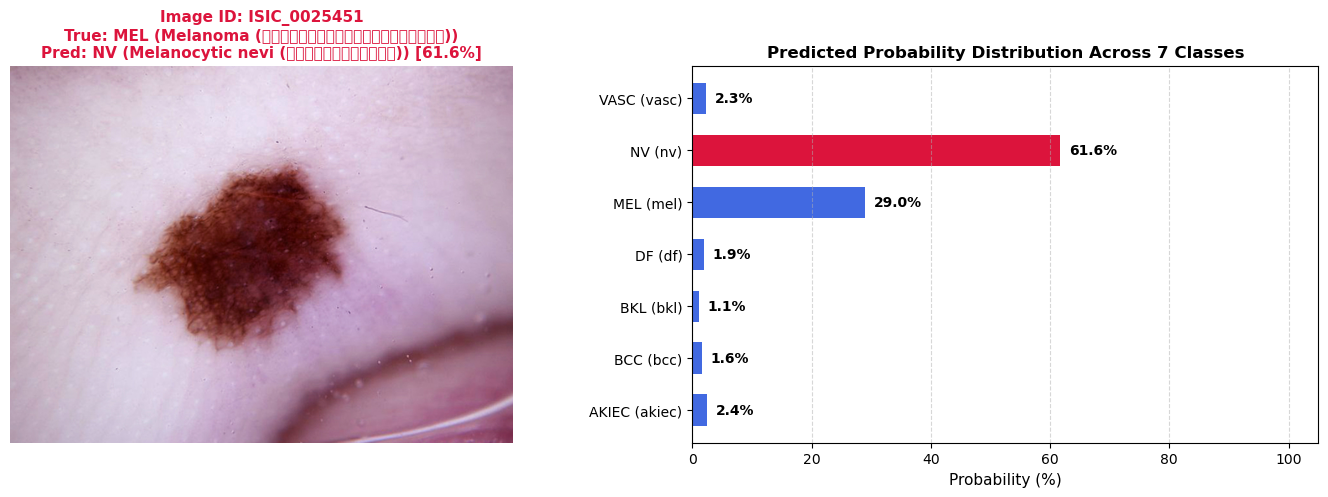

In [4]:
# =========================================================================
# 4. ทำนายภาพเดี่ยวพร้อมดูกราฟแท่งความมั่นใจ (Confidence Bar Chart)
# =========================================================================
splits_df = pd.read_csv('splits/splits.csv')
test_df = splits_df[splits_df['split'] == 'test'].reset_index(drop=True)

# สุ่มตัวอย่างภาพที่เป็นมะเร็ง (Melanoma: mel) มา 1 ภาพ
mel_samples = test_df[test_df['dx'] == 'mel']
sample_row = mel_samples.iloc[0]
img_path = find_image_path(sample_row['image_id'])

result = predict_lesion(img_path, model, transform, device)
true_cls = sample_row['dx']
pred_cls = result['pred_class']

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(14, 5))

# 1. แสดงรูปภาพรอยโรค
ax_img.imshow(result['pil_image'])
is_correct = (true_cls == pred_cls)
title_color = 'darkgreen' if is_correct else 'crimson'
ax_img.set_title(f"Image ID: {sample_row['image_id']}\nTrue: {true_cls.upper()} ({CLASS_DESC[true_cls]})\nPred: {pred_cls.upper()} ({CLASS_DESC[pred_cls]}) [{result['confidence']:.1f}%]",
                 fontsize=11, fontweight='bold', color=title_color)
ax_img.axis('off')

# 2. กราฟแท่งแสดง Softmax Probability ทุกคลาส
colors = ['royalblue' if c != pred_cls else ('forestgreen' if is_correct else 'crimson') for c in CLASSES]
y_pos = np.arange(len(CLASSES))
probs_pct = result['probs'] * 100

bars = ax_bar.barh(y_pos, probs_pct, color=colors, height=0.6)
ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels([f"{c.upper()} ({c})" for c in CLASSES], fontsize=10)
ax_bar.set_xlabel('Probability (%)', fontsize=11)
ax_bar.set_xlim(0, 105)
ax_bar.set_title('Predicted Probability Distribution Across 7 Classes', fontsize=12, fontweight='bold')
ax_bar.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    width = bar.get_width()
    if width > 0.5:
        ax_bar.annotate(f'{width:.1f}%',
                        xy=(width + 1.5, bar.get_y() + bar.get_height() / 2),
                        va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

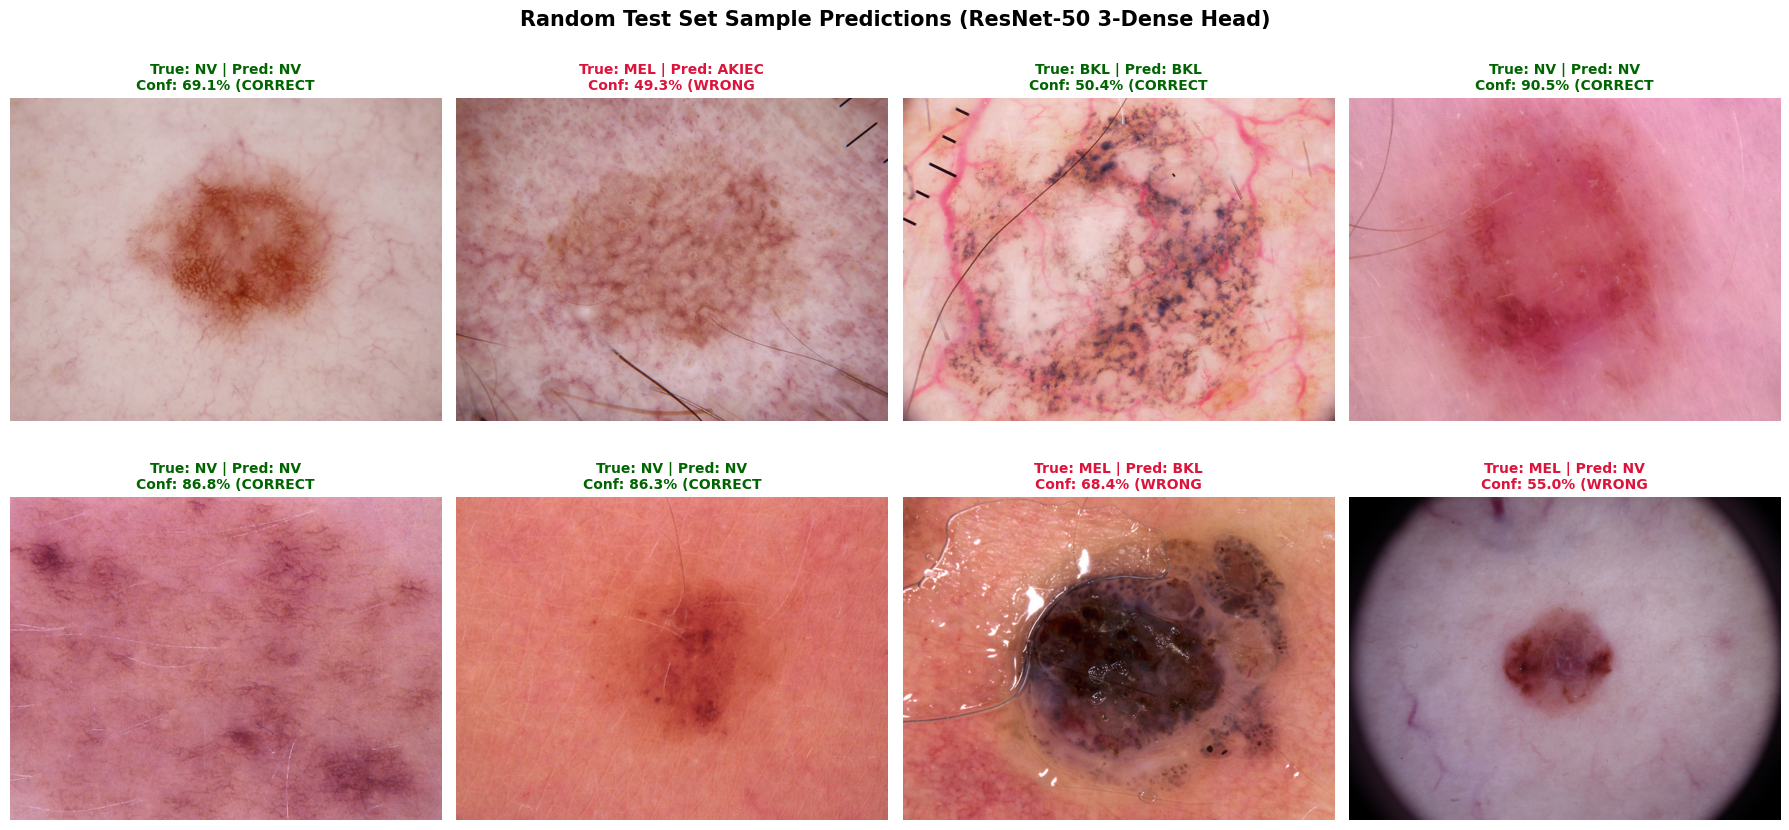

In [5]:
# =========================================================================
# 5. สุ่มทดสอบ 8 ภาพจริงจาก Test Set (Grid Visualization)
# =========================================================================
random.seed(42)
sample_indices = random.sample(range(len(test_df)), 8)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, idx in enumerate(sample_indices):
    row = test_df.iloc[idx]
    img_p = find_image_path(row['image_id'])
    res = predict_lesion(img_p, model, transform, device)

    t_cls = row['dx']
    p_cls = res['pred_class']
    correct = (t_cls == p_cls)
    border_color = 'green' if correct else 'red'

    axes[i].imshow(res['pil_image'])
    axes[i].set_title(
        f"True: {t_cls.upper()} | Pred: {p_cls.upper()}\nConf: {res['confidence']:.1f}% ({'CORRECT' if correct else 'WRONG'}",
        fontsize=10,
        fontweight='bold',
        color='darkgreen' if correct else 'crimson'
    )
    axes[i].axis('off')

plt.suptitle('Random Test Set Sample Predictions (ResNet-50 3-Dense Head)', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [6]:
# =========================================================================
# 6. ทดสอบทำนายภาพระบุ Image ID หรือภาพเฉพาะเจาะจง
# =========================================================================
# ใส่ Image ID ใดๆ ที่ต้องการทดสอบ (เช่น ISIC_0033084)
test_image_id = test_df.iloc[15]['image_id']

img_path = find_image_path(test_image_id)
custom_res = predict_lesion(img_path, model, transform, device)

print('=' * 60)
print(f'ผลการวิเคราะห์รอยโรคสำหรับภาพ: {test_image_id}')
print('=' * 60)
print(f"โรคที่ทำนายได้ : {custom_res['pred_class'].upper()} - {CLASS_DESC[custom_res['pred_class']]}")
print(f"ความมั่นใจ      : {custom_res['confidence']:.2f}%")
print('=' * 60)
print('สัดส่วนความน่าจะเป็นทุกคลาส (Probability Ranking):')
sorted_indices = np.argsort(custom_res['probs'])[::-1]
for rank, c_idx in enumerate(sorted_indices, 1):
    c_name = CLASSES[c_idx]
    p = custom_res['probs'][c_idx] * 100
    print(f"{rank}. {c_name.upper():<6} : {p:>6.2f}% ({CLASS_DESC[c_name]})")
print('=' * 60)

ผลการวิเคราะห์รอยโรคสำหรับภาพ: ISIC_0033466
โรคที่ทำนายได้ : NV - Melanocytic nevi (ไฝปกติทั่วไป)
ความมั่นใจ      : 93.53%
สัดส่วนความน่าจะเป็นทุกคลาส (Probability Ranking):
1. NV     :  93.53% (Melanocytic nevi (ไฝปกติทั่วไป))
2. BKL    :   3.15% (Benign keratosis (ติ่งเนื้อ/กระเนื้อ))
3. MEL    :   0.89% (Melanoma (มะเร็งเมลาโนมารุนแรง))
4. BCC    :   0.70% (Basal cell ca. (มะเร็งผิวหนัง))
5. DF     :   0.64% (Dermatofibroma (ก้อนเนื้อไฟโบรมา))
6. VASC   :   0.59% (Vascular lesion (หลอดเลือดผิดปกติ))
7. AKIEC  :   0.49% (Actinic keratoses (ระยะก่อนมะเร็ง))
